In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
import re
import bs4 as bs
import gensim
from gensim.models import Word2Vec
from nltk.tokenize import sent_tokenize,word_tokenize
import nltk
import urllib.request
%matplotlib inline
import seaborn as sns

In [3]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [6]:
# sentences = """Alice 23 opened the door and found that it led into a small 90
# passage, not much larger than a rat-hole: she knelt down and
# looked along the passage into the loveliest garden you ever saw.
# How she longed to get out of that dark hall, and wander about
# among those beds of bright flowers and those cool fountains, but
# she could not even get her head through the doorway; `and even if
# my head would go through,' (thought) $poor Alice, `it would be of
# very little use without my shoulders. Oh, how I wish
# I could shut up like a telescope! I think I could, if I only
# know how to begin.' For, you see, so many out-of-the-way things
# had happened lately, that Alice had begun to think that very few
# things indeed were really impossible."""
sentences=""" My name is Sanika Deokar, and I am pursuing my engineering degree at PVG College. I am interested in Artificial Intelligence and Machine Learning because I enjoy learning about new technologies. My strengths are that I am hardworking, dedicated, and willing to learn new things. My weakness is that sometimes I overthink and take extra time to complete tasks, but I am working on improving myself. My hobbies include drawing, painting, and exploring creative activities. I like learning new skills and improving my knowledge. My goal is to become a successful engineer and build a good career in the technology field."""

In [7]:
sentences=re.sub('[^A-Za-z]+', ' ' , sentences)

In [8]:
sentences=re.sub(r'(?:^| )\w(?:$| )', ' ' , sentences).strip()
sentences=sentences.lower()
print(sentences)

my name is sanika deokar and am pursuing my engineering degree at pvg college am interested in artificial intelligence and machine learning because enjoy learning about new technologies my strengths are that am hardworking dedicated and willing to learn new things my weakness is that sometimes overthink and take extra time to complete tasks but am working on improving myself my hobbies include drawing painting and exploring creative activities like learning new skills and improving my knowledge my goal is to become successful engineer and build good career in the technology field


In [9]:
all_sent=nltk.sent_tokenize(sentences)
all_words=[nltk.word_tokenize(word) for word in all_sent]
from nltk.corpus import stopwords
for i in range(len(all_words)):
    all_words[i]=[w for w in all_words[i] if w not in stopwords.words('english')]
    data=all_words
    data1=data[0]

In [10]:
model1=gensim.models.Word2Vec(data, min_count=1,vector_size=52,window=5)

In [11]:
vocabolary=model1.wv.key_to_index
vocabolary

{'new': 0,
 'learning': 1,
 'improving': 2,
 'field': 3,
 'technology': 4,
 'career': 5,
 'good': 6,
 'build': 7,
 'engineer': 8,
 'successful': 9,
 'become': 10,
 'goal': 11,
 'knowledge': 12,
 'skills': 13,
 'like': 14,
 'activities': 15,
 'creative': 16,
 'exploring': 17,
 'painting': 18,
 'drawing': 19,
 'include': 20,
 'hobbies': 21,
 'working': 22,
 'tasks': 23,
 'complete': 24,
 'time': 25,
 'extra': 26,
 'take': 27,
 'overthink': 28,
 'sometimes': 29,
 'weakness': 30,
 'things': 31,
 'learn': 32,
 'willing': 33,
 'dedicated': 34,
 'hardworking': 35,
 'strengths': 36,
 'technologies': 37,
 'enjoy': 38,
 'machine': 39,
 'intelligence': 40,
 'artificial': 41,
 'interested': 42,
 'college': 43,
 'pvg': 44,
 'degree': 45,
 'engineering': 46,
 'pursuing': 47,
 'deokar': 48,
 'sanika': 49,
 'name': 50}

In [12]:
wrd='name'
v1=model1.wv[wrd]
sim=model1.wv.most_similar(wrd)
for x in sim:
 print(x)

('tasks', 0.2906421422958374)
('like', 0.2783222794532776)
('machine', 0.2677539587020874)
('technology', 0.25060829520225525)
('learn', 0.22453470528125763)
('sanika', 0.21062679588794708)
('drawing', 0.17551663517951965)
('intelligence', 0.17185482382774353)
('working', 0.16905631124973297)
('improving', 0.13679243624210358)


In [13]:
print(data1)
dat=[]
for i in range(2,len(data1)-2):
  context=[data1[i-2],data1[i-1],data1[i+1],data1[i+2]]
  target =data1[i]
  dat.append((context,target))
print(dat[:5])
if len(dat)>1:
  print(dat[1][0])
else:
    print("no enought data")

['name', 'sanika', 'deokar', 'pursuing', 'engineering', 'degree', 'pvg', 'college', 'interested', 'artificial', 'intelligence', 'machine', 'learning', 'enjoy', 'learning', 'new', 'technologies', 'strengths', 'hardworking', 'dedicated', 'willing', 'learn', 'new', 'things', 'weakness', 'sometimes', 'overthink', 'take', 'extra', 'time', 'complete', 'tasks', 'working', 'improving', 'hobbies', 'include', 'drawing', 'painting', 'exploring', 'creative', 'activities', 'like', 'learning', 'new', 'skills', 'improving', 'knowledge', 'goal', 'become', 'successful', 'engineer', 'build', 'good', 'career', 'technology', 'field']
[(['name', 'sanika', 'pursuing', 'engineering'], 'deokar'), (['sanika', 'deokar', 'engineering', 'degree'], 'pursuing'), (['deokar', 'pursuing', 'degree', 'pvg'], 'engineering'), (['pursuing', 'engineering', 'pvg', 'college'], 'degree'), (['engineering', 'degree', 'college', 'interested'], 'pvg')]
['sanika', 'deokar', 'engineering', 'degree']


In [14]:
for val in dat:
    print(val[1],val[0])
    i=3
if len(dat)>3:
    print(dat[i])
    print(model1.predict_output_word(dat[i][0]))
else:
    print("no index")
    
    

deokar ['name', 'sanika', 'pursuing', 'engineering']
pursuing ['sanika', 'deokar', 'engineering', 'degree']
engineering ['deokar', 'pursuing', 'degree', 'pvg']
degree ['pursuing', 'engineering', 'pvg', 'college']
pvg ['engineering', 'degree', 'college', 'interested']
college ['degree', 'pvg', 'interested', 'artificial']
interested ['pvg', 'college', 'artificial', 'intelligence']
artificial ['college', 'interested', 'intelligence', 'machine']
intelligence ['interested', 'artificial', 'machine', 'learning']
machine ['artificial', 'intelligence', 'learning', 'enjoy']
learning ['intelligence', 'machine', 'enjoy', 'learning']
enjoy ['machine', 'learning', 'learning', 'new']
learning ['learning', 'enjoy', 'new', 'technologies']
new ['enjoy', 'learning', 'technologies', 'strengths']
technologies ['learning', 'new', 'strengths', 'hardworking']
strengths ['new', 'technologies', 'hardworking', 'dedicated']
hardworking ['technologies', 'strengths', 'dedicated', 'willing']
dedicated ['strengths', 

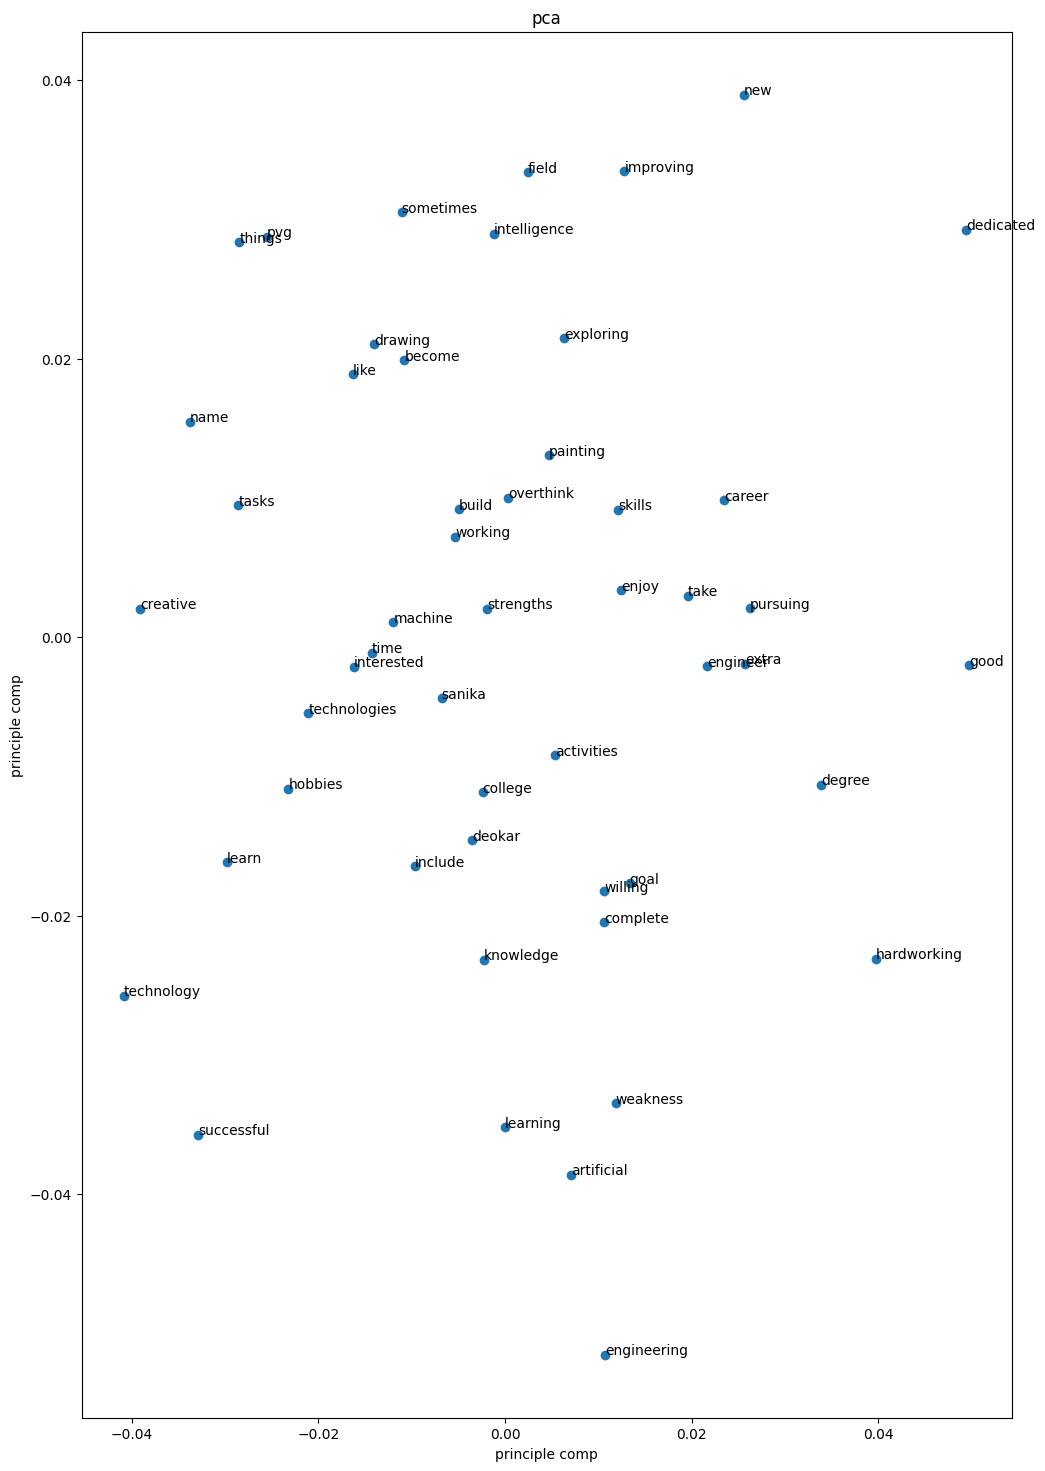

In [15]:
from sklearn.decomposition import PCA
words=model1.wv.index_to_key
X=model1.wv[words]
pca=PCA(n_components=2)
result=pca.fit_transform(X)
plt.figure(figsize=(12,18))
plt.scatter(result[:,0],result[:,1])
for i,word in enumerate(words):
    plt.annotate(word,xy=(result[i,0],result[i,1]))
plt.xlabel('principle comp')
plt.ylabel('principle comp')
plt.title('pca')
plt.show()

    
